In [1]:
# import libs
import os 
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import sys
import scanpy as sc 
import pandas as pd 
import numpy as np 
import anndata as ad
import leidenalg
import scanpy.external as sce
import cellrank as cr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import decoupler
import pydeseq2
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import gseapy as gp
from gseapy.plot import gseaplot
import seaborn as sns
import networkx as nx
import igraph as ig
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
env_path = "../.env"
# call paths from .env
if os.path.exists(env_path):
    with open(env_path) as f:
        os.environ.update(
            line.strip().split("=", 1) for line in f
            if line.strip() and not line.startswith("#")
        )
        
plots_dir = os.getenv("PLOTS_DIR")
processed_adata_dir = os.getenv("PROCESSED_ANNDATA_DIR")
src_dir = os.getenv("SRC_DIR")

In [3]:
# load anndata 
adata = sc.read_h5ad(processed_adata_dir + "Adata_subclustered.h5ad")

/tmp/ipykernel_1658806/4165049847.py:11: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


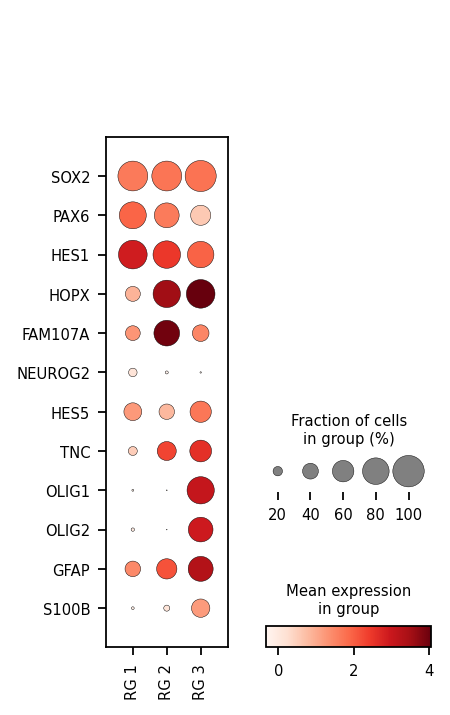

In [4]:
# Plot the dotplot
markers = ['SOX2', 'PAX6', 'HES1', 'HOPX', 'FAM107A', 'NEUROG2', 'HES5', 'TNC', 'OLIG1', 'OLIG2', 'GFAP', 'S100B']

sc.set_figure_params(fontsize=8)

# subset to hs_ncx RG
adata_hs_ncx = adata[adata.obs['dataset_of_origin'].isin(['Trevino', 'Polioudakis'])].copy()

sc.pl.dotplot(adata_hs_ncx, markers, groupby ='leiden_subclustered_G1 RG', 
              mean_only_expressed = False, show = False, cmap = 'Reds', swap_axes=True)
plt.tight_layout()
plt.savefig(plots_dir + 'clustering/Dotplot_RG_human_ncx_subsets.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

In [5]:
# switch to raw counts
adata.X = adata.layers['counts'].copy()

In [6]:
# build pseudobulk replicates
pdata = decoupler.get_pseudobulk(
    adata=adata,
    sample_col="sample_id",
    groups_col="leiden_subclustered_G1 RG",
    mode="sum",
    min_cells = 15, 
    min_counts = 20000
)

In [7]:
# save pdata
pdata.write_h5ad(processed_adata_dir + 'pdata_pseudobulked_RG_subclusters.h5ad')

In [8]:
paired_samples = ['S_368', 'hft_w20_p3_r1', 'hft_w20_p3_r2','hft_w21_p5_r1', 'hft_w21_p5_r2',
                  'hft_w24_p6_r1', 'hft_w24_p6_r2']

rg1_vs_rg3 = pdata[
    (pdata.obs['sample_id'].isin(paired_samples)) &
    (pdata.obs['leiden_subclustered_G1 RG'].isin(['RG 1', 'RG 3'])) &
    (pdata.obs['species'] == 'human_ncx')
].copy()

In [9]:
# ensure raw counts
rg1_vs_rg3.layers['counts'] = rg1_vs_rg3.X.copy()

In [10]:
# prepare the deseq object
dds = DeseqDataSet(
    adata = rg1_vs_rg3,   
    design_factors= ['sample_id','leiden_subclustered_G1 RG'],
    ref_level=['leiden_subclustered_G1 RG', 'RG 1'],
    refit_cooks=True)

/tmp/ipykernel_1658806/1857054872.py:2: UserWarning: Same factor names in the design contain underscores ('_'). They will
                be converted to hyphens ('-').
  dds = DeseqDataSet(
/usr/local/lib/python3.10/dist-packages/pydeseq2/dds.py:270: UserWarning: Some factor levels in the design contain underscores ('_').
                    They will be converted to hyphens ('-').
  self.obsm["design_matrix"] = build_design_matrix(


In [11]:
# perform deseq2
dds.deseq2() 

Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 3.01 seconds.

Fitting dispersion trend curve...
... done in 0.26 seconds.

Fitting MAP dispersions...
... done in 3.89 seconds.

Fitting LFCs...
... done in 3.25 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [12]:
# output results
stat_res = DeseqStats(dds, contrast=['leiden-subclustered-G1 RG', 'RG 3', 'RG 1'])
stat_res.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: leiden-subclustered-G1 RG RG 3 vs RG 1
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG      0.000000             NaN       NaN       NaN       NaN       NaN
A2M       0.206104        0.683990  3.275713  0.208807  0.834599       NaN
A3GALT2   0.000000             NaN       NaN       NaN       NaN       NaN
A4GALT    0.000000             NaN       NaN       NaN       NaN       NaN
AAAS     10.988864       -0.315687  0.288166 -1.095504  0.273296  0.608072
...            ...             ...       ...       ...       ...       ...
ZXDC      8.404335        0.218921  0.333430  0.656574  0.511455  0.787141
ZYG11B   29.560971        0.198752  0.201733  0.985221  0.324515  0.657111
ZYX      25.681801        0.551274  0.203975  2.702652  0.006879  0.051024
ZZEF1     7.458048        0.249168  0.343304  0.725794  0.467965  0.759668
ZZZ3     29.536247       -0.014163  0.205667 -0.068862  0.945100  0.981591

[14761 rows x 6 column

... done in 1.38 seconds.



In [13]:
# output df
results_df = stat_res.results_df
results_df = results_df[results_df["baseMean"] > 1]

# reindex df
results_df_ss = results_df.copy()
results_df_ss.reset_index(inplace=True)
results_df_ss.rename(columns ={'index':'gene_name'}, inplace = True)

In [14]:
# convert to -log10padj and cap
results_df['log_10_padj'] = -np.log10(results_df['padj'])
cap = 10
results_df['log_10_padj_capped'] = np.where(results_df['log_10_padj']>cap, cap, results_df['log_10_padj'])

In [15]:
# filter p adjusted 
results_df_ss = results_df[results_df['padj'] < 0.05]
# filtr log2FC
degs_rg1_up = results_df_ss[results_df_ss['log2FoldChange'] > 1]
degs_rg1_down = results_df_ss[results_df_ss['log2FoldChange'] < -1]
# print the number of up and down-regulated genes
print(f"Up-regulated in RG3 : {len(degs_rg1_up)}")
print(f"Down-reglated in RG3 : {len(degs_rg1_down)}")

Up-regulated in RG3 : 435
Down-reglated in RG3 : 438


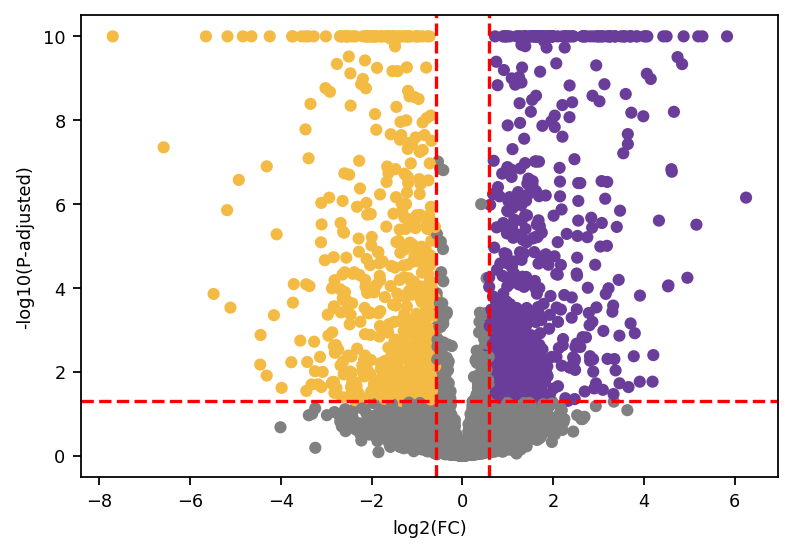

In [16]:
script_path = plots_dir + 'Volcano_plot.py'
%run -i $script_path
# Plot the volcano plot
volcano_plot(df = results_df, df_up=degs_rg1_up, df_down=degs_rg1_down, top_genes = 0)
plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + 'degs/hs_ncx_RG/Volcano_HS_RG3_vs_RG1_DEGs.png', dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + 'degs/hs_ncx_RG/Volcano_HS_RG3_vs_RG1_DEGs.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

In [17]:
# extract top 10 up and down-regulated genes
top_10_up  = results_df.sort_values(by = 'log2FoldChange', ascending = False).reset_index()['index'].head(10).tolist()
top_10_down  = results_df.sort_values(by = 'log2FoldChange', ascending = True).reset_index()['index'].head(10).tolist()
top_genes = top_10_up + top_10_down

In [18]:
# subset results_df to include only top 10 up and down-regulated genes
results_df_top = results_df.loc[results_df.index.isin(top_genes), ['log2FoldChange']]
results_df_top = results_df_top.sort_values(by="log2FoldChange", ascending=False)

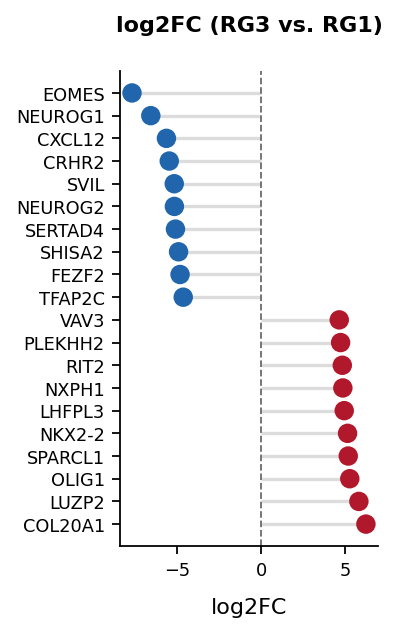

In [19]:
# plot a lollipop plot
fig, ax = plt.subplots(figsize=(2.5, 4))

colors = np.where(results_df_top["log2FoldChange"] > 0, "#b2182b", "#2166ac")

ax.hlines(
    y=results_df_top.index,
    xmin=0,
    xmax=results_df_top["log2FoldChange"],
    color="gainsboro",
    linewidth=1.5,
)
ax.scatter(
    results_df_top["log2FoldChange"],
    results_df_top.index,
    color=colors,
    s=60,
    zorder=3,
)

ax.axvline(x=0, color="dimgray", linestyle="--", linewidth=0.8)

ax.set_title("log2FC (RG3 vs. RG1)", fontsize=10, pad=18, weight="bold")
ax.set_xlabel("log2FC", fontsize=10, labelpad = 8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.tick_params(axis='y', labelsize=8)

plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + 'degs/hs_ncx_RG/Lollipop_HS_RG3_vs_RG1_top.png', dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + 'degs/hs_ncx_RG/Lollipop_HS_RG3_vs_RG1_top.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

### TF inference

In [20]:
# extract stat values
mat = results_df[['stat']].T.rename(index={'stat': 'rg3_vs_rg1'})

In [21]:
# download collectri
url = "https://omnipathdb.org/interactions?datasets=collectri&format=tsv&genesymbols=1&organisms=9606"
raw_net = pd.read_csv(url, sep="\t")
raw_net["weight"] = (raw_net["is_stimulation"].astype(int) - raw_net["is_inhibition"].astype(int))

collectri_df = (
    raw_net.groupby(["source_genesymbol", "target_genesymbol"])["weight"]
    .mean()
    .reset_index())

# rename cols 
collectri_df = collectri_df.rename(columns={'source_genesymbol': 'source', 'target_genesymbol': 'target'})

In [22]:
# run ULM
tf_acts, tf_pvals = decoupler.run_ulm(
    mat=mat,
    net=collectri_df, 
    source="source",
    target="target",
    weight="weight",
    use_raw=False,
    verbose=True
)

Running ulm on mat with 1 samples and 11130 targets for 595 sources.


In [23]:
# fitler tf_acts
tf_acts_filtered = tf_acts.where(tf_pvals < 0.05, 0)
tf_acts_filtered = tf_acts_filtered.loc[:, (tf_acts_filtered != 0).any()]

In [24]:
# filter top 10 up and down-regulated TFs 
tf_top10_up = tf_acts_filtered.T.sort_values(by='rg3_vs_rg1', ascending = False).head(10).reset_index()
tf_top10_down = tf_acts_filtered.T.sort_values(by='rg3_vs_rg1', ascending = True).head(10).reset_index()

tf_top = pd.concat([tf_top10_up, tf_top10_down], axis=0).reset_index(drop=True)
tf_top = tf_top.sort_values(by="rg3_vs_rg1", ascending=False)

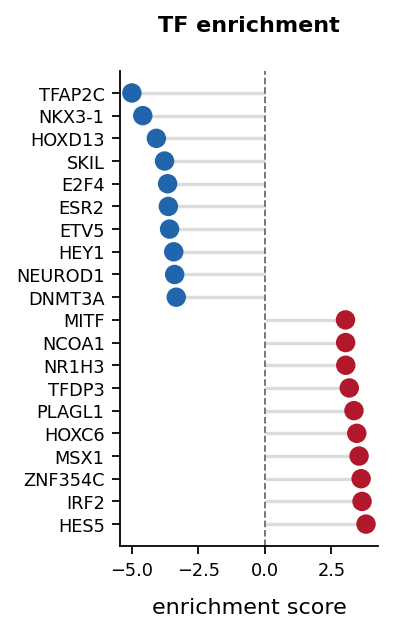

In [25]:
# plot a lollipop
fig, ax = plt.subplots(figsize=(2.5, 4))

colors = np.where(tf_top["rg3_vs_rg1"] > 0, "#b2182b", "#2166ac")

ax.hlines(
    y=tf_top["index"],
    xmin=0,
    xmax=tf_top["rg3_vs_rg1"],
    color="gainsboro",
    linewidth=1.5,
)

ax.scatter(
    tf_top["rg3_vs_rg1"],
    tf_top["index"],
    color=colors,
    s=60,
    zorder=3,
)

ax.axvline(x=0, color="dimgray", linestyle="--", linewidth=0.8)

ax.set_title("TF enrichment", fontsize=10, pad=18, weight="bold")
ax.set_xlabel("enrichment score", fontsize=10, labelpad=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle=":", alpha=0.6)

ax.tick_params(axis="y", labelsize=8)

plt.grid(False)
plt.tight_layout()
plt.savefig(plots_dir + 'degs/hs_ncx_RG/Lollipop_HS_RG3_vs_RG1_enriched_TF.png', dpi = 300, bbox_inches = 'tight')
plt.savefig(plots_dir + 'degs/hs_ncx_RG/Lollipop_HS_RG3_vs_RG1_enriched_TF.svg', dpi = 300, bbox_inches = 'tight')
plt.show()

/group/kalebic/Nikola/1_single_cell_final/Nikola_final/final/scdgomics/src/network_plot.py:144: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


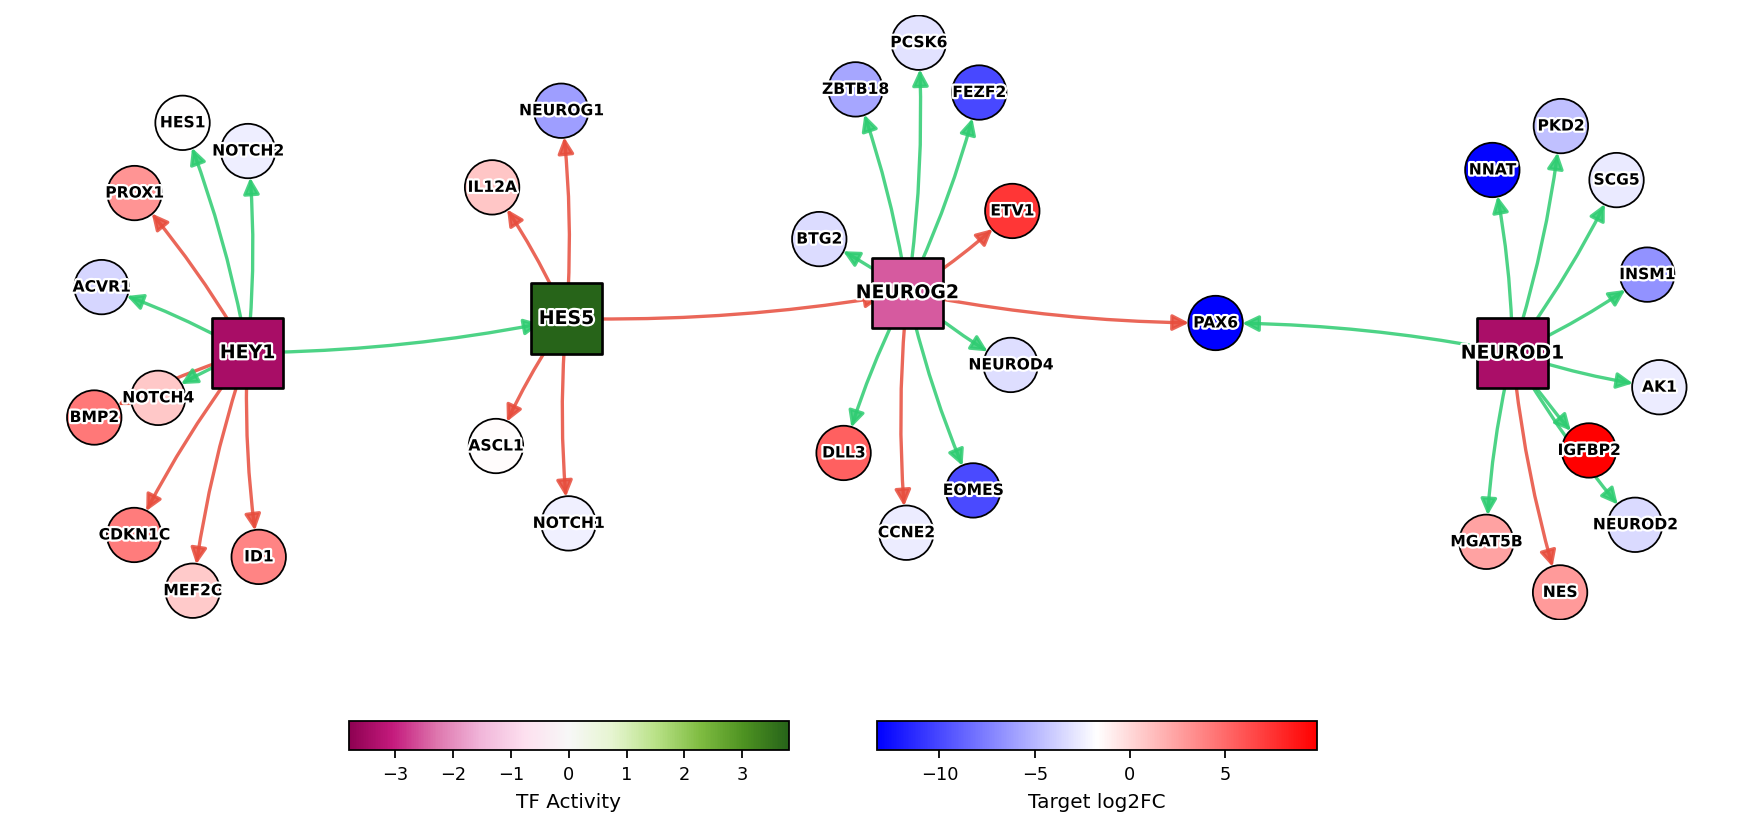

In [26]:
script_path = src_dir + 'network_plot.py'
%run -i $script_path

network_plot(source_genes = ['HES5', 'NEUROD1', 'NEUROG2', 'HEY1'], n_targets = 10, collectri_df = collectri_df, mat = mat, tf_acts = tf_acts, results_df = results_df, save_fig = True, save_path = 'degs/hs_ncx_RG/Igraph_RG3_vs_RG1_enriched_network.png'
            )

In [27]:
# sanity check - glial populations should increase with time; neurogenic populations should decrease with time
adata_full = sc.read_h5ad(processed_adata_dir + 'Adata_clustered.h5ad')
# subsample to hs_ncx 
adata_full.obs['species'] = adata_full.obs['dataset_of_origin'].map({
    'Polioudakis': 'human_ncx',
    'Trevino': 'human_ncx', 
    'Linnarsson': 'mouse_dg', 
    'Zylka': 'mouse_ncx', 
    'Ruan': 'mouse_ncx', 
    'Zhong': 'human_dg'
})
adata_hs_ncx = adata_full[adata_full.obs['species'] == 'human_ncx'].copy()
# sample_id df 
df_id = adata_hs_ncx.obs["sample_id"]
df_id = pd.DataFrame(df_id)

In [28]:
# map sample ids to GW in full df 
gw_map = {
    "S_368": "GW17", "S_371": "GW17",
    "S_370": "GW18", "S_372": "GW18",
    "hft_w16_p7_r1": "GW16", "hft_w16_p7_r2": "GW16",
    "hft_w20_p3_r1": "GW20", "hft_w20_p3_r2": "GW20",
    "hft_w21_p5_r1": "GW21", "hft_w21_p5_r2": "GW21",
    "hft_w24_p6_r1": "GW24", "hft_w24_p6_r2": "GW24",
}

df_id['GW_info'] = df_id['sample_id'].map(gw_map)
df_id['GW_info'].unique()

array(['GW17', 'GW18', 'GW20', 'GW21', 'GW24', 'GW16'], dtype=object)

In [29]:
# map sample ids to GW in RG-subsampled df
df_id_ss = adata.obs[["sample_id", "leiden_subclustered_G1 RG"]]
df_id_ss

df_id_ss['GW_info'] = df_id_ss['sample_id'].map(gw_map)
df_id_ss['GW_info'].unique()

array(['GW17', 'GW18', 'GW20', 'GW21', 'GW24', 'GW16', nan], dtype=object)

In [30]:
# make a crosstab
df_glio_rg = pd.crosstab(df_id_ss["GW_info"], adata.obs["leiden_subclustered_G1 RG"])
df_glio_rg = df_glio_rg.reset_index()
# melt 
df_glio_rg_melted = pd.melt(df_glio_rg, id_vars = ["GW_info"], value_vars = ['RG 1', 'RG 2', 'RG 3'], 
                            var_name = 'Subcluster', value_name = 'Number')

In [31]:
# merge
df_id['total_cells'] = df_id['GW_info'].map(df_id['GW_info'].value_counts())
df_merged = df_glio_rg_melted.merge(df_id, on='GW_info', how='left')

In [32]:
# compute percent of RG 1, 2, 3 out of total cell number per GW
df_merged['percent_expressed'] = df_merged['Number']/ df_merged['total_cells']

In [33]:
df_plot = df_merged.drop_duplicates(subset=[ 'percent_expressed'])

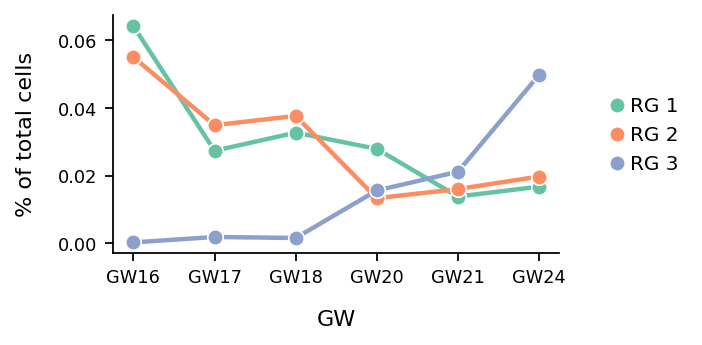

In [34]:
# plot a lineplot
fig, ax = plt.subplots(figsize=(4.5, 2.2))

sns.lineplot(
    data=df_plot,
    x="GW_info",
    y="percent_expressed",
    hue="Subcluster",
    marker="o", 
    markeredgecolor="white",
    linewidth=2,
    markersize=7,
    palette="Set2",
    ax=ax,
)

ax.set_xlabel("GW", fontsize=10, labelpad = 10)
ax.set_ylabel("% of total cells", fontsize=10, labelpad = 10)
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=8)

ax.legend(
    title=None, 
    loc=(1.1, 0.3),
    frameon=True, 
    facecolor="white", 
    edgecolor="none",
    fontsize=9
)

sns.despine()
plt.tight_layout()
plt.grid(False)
plt.savefig(plots_dir + 'degs/hs_ncx_RG/Lineplot_HS_RG_subclusters_across_GW.png', dpi = 300, bbox_inches = 'tight')
plt.show()